# 02 · Validación del IRAT — FireWatch Boyacá

**Dueño:** B · **Tarea:** B9 · **Entrada:** `data/gold/fact_municipio_mes.csv` · **Referencia:** Arquitectura §7.3

In [1]:
# === Celda 0 · Carga del gold (data freeze) y verificación ===
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GOLD = RAIZ / "data" / "gold"
FIG = RAIZ / "docs" / "figures" / "validacion"
FIG.mkdir(parents=True, exist_ok=True)

fmm = pd.read_parquet(GOLD / "fact_municipio_mes.parquet")
sens = pd.read_parquet(GOLD / "_analisis" / "irat_sensibilidad.parquet")
dim = pd.read_parquet(GOLD / "dim_municipio.parquet")
for d in (fmm, sens):
    d["fecha_mes"] = pd.to_datetime(d["fecha_mes"])

# El gold debe ser el del data freeze (gold_validation.json): 7.134 municipio-mes y K1 = 3.908
assert len(fmm) == 7134 and len(sens) == 7134
assert int(fmm["n_det"].sum()) == 3908 and int(sens["n_det"].sum()) == 3908

CATS = ["Muy bajo", "Bajo", "Moderado", "Alto", "Muy alto"]
VARIANTES = {
    "Oficial": ("irat", "irat_orden"),
    "Pesos iguales": ("irat_iguales", "orden_iguales"),
    "Solo clima (sin H)": ("irat_solo_clima", "orden_solo_clima"),
}
con_det = int((fmm["n_det"] > 0).sum())
print(f"municipio-mes con al menos una detección: {con_det} de {len(fmm)} ({con_det / len(fmm):.1%})")

municipio-mes con al menos una detección: 807 de 7134 (11.3%)


## 1. Distribución del IRAT y de sus componentes

,celdas,detecciones,% celdas,% detecciones
irat_categoria,,,,
Muy bajo,1427,64,20.0,1.6
Bajo,1427,89,20.0,2.3
Moderado,1426,443,20.0,11.3
Alto,1427,695,20.0,17.8
Muy alto,1427,2617,20.0,67.0


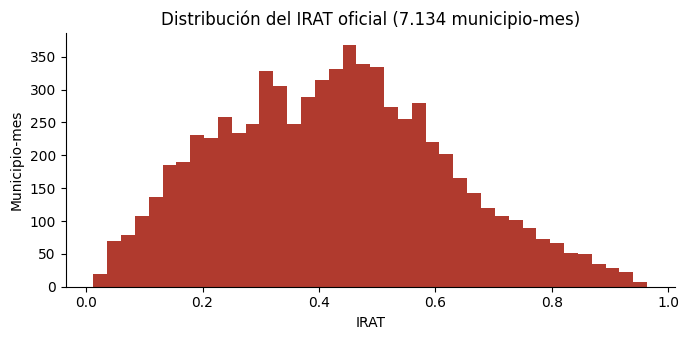

In [2]:
# === Celda 1 · Distribución del IRAT y detecciones por categoría ===
t = (fmm.groupby("irat_categoria")
        .agg(celdas=("n_det", "size"), detecciones=("n_det", "sum"))
        .reindex(CATS))
t["% celdas"] = (100 * t["celdas"] / t["celdas"].sum()).round(1)
t["% detecciones"] = (100 * t["detecciones"] / t["detecciones"].sum()).round(1)
display(t)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(fmm["irat"], bins=40, color="#b03a2e")
ax.set_xlabel("IRAT")
ax.set_ylabel("Municipio-mes")
ax.set_title("Distribución del IRAT oficial (7.134 municipio-mes)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Hallazgo 1.** Los quintiles quedan exactos (20,0 % de las celdas en cada categoría), pero las detecciones no se reparten igual: Muy alto concentra 2.617 de las 3.908 (67,0 %) y Alto 695 (17,8 %), mientras Muy bajo y Bajo juntas suman 153 (3,9 %). La distribución del IRAT tiene escalones porque la mayoría de las celdas tiene `c_H` empatado en cero (sin historia de detecciones).

## 2. ρ de Spearman concurrente: IRAT(t) vs detecciones(t)

In [3]:
# === Celda 2 · Spearman concurrente y anticipado, por variante ===
def spearman_variante(col: str) -> dict:
    d = sens.sort_values(["cod_mpio", "fecha_mes"]).copy()
    # detecciones del mes siguiente dentro de cada municipio (la grilla mensual está completa)
    d["n_det_sig"] = d.groupby("cod_mpio")["n_det"].shift(-1)
    m = d.dropna(subset=["n_det_sig"])
    # escala departamental: IRAT medio del mes vs total de detecciones del mes
    dep = d.groupby("fecha_mes").agg(x=(col, "mean"), y=("n_det", "sum")).sort_index()
    x_ant = dep["x"].iloc[:-1].reset_index(drop=True)
    y_sig = dep["y"].iloc[1:].reset_index(drop=True)
    return {
        "rho_t": d[col].corr(d["n_det"], method="spearman"),
        "n_t": len(d),
        "rho_t+1": m[col].corr(m["n_det_sig"], method="spearman"),
        "n_t+1": len(m),
        "rho_dep_t": dep["x"].corr(dep["y"], method="spearman"),
        "rho_dep_t+1": x_ant.corr(y_sig, method="spearman"),
        "meses": len(dep),
    }

res = pd.DataFrame({nombre: spearman_variante(col) for nombre, (col, _) in VARIANTES.items()}).T
res["captura_alto_muy_alto"] = [
    sens.loc[sens[orden] >= 4, "n_det"].sum() / sens["n_det"].sum() for _, orden in VARIANTES.values()
]
res[["n_t", "n_t+1", "meses"]] = res[["n_t", "n_t+1", "meses"]].astype(int)
display(res.round(3))

,rho_t,n_t,rho_t+1,n_t+1,rho_dep_t,rho_dep_t+1,meses,captura_alto_muy_alto
Oficial,0.287,7134.0,0.241,7011.0,0.382,0.240,58.0,0.847
Pesos iguales,0.213,7134.0,0.170,7011.0,0.316,0.199,58.0,0.752
Solo clima (sin H),0.099,7134.0,0.067,7011.0,0.241,0.182,58.0,0.607


**Hallazgo 2.** El ρ concurrente del IRAT oficial es 0,287 (n = 7.134): positivo, pero moderado-bajo. La razón principal es estadística: el 88,7 % de los municipio-mes no tiene detecciones (solo 807 tienen al menos una), y esos miles de empates en cero limitan cualquier correlación de rangos. A escala departamental (58 meses) el ρ sube a 0,382. No se reportan p-valores por la autocorrelación espacial y temporal (mismo criterio del EDA).

## 3. ρ de Spearman anticipado: IRAT(t) vs detecciones(t+1)

**Hallazgo 3.** El ρ anticipado (IRAT del mes *t* frente a detecciones del mes *t*+1) baja a 0,241 (n = 7.011) y a 0,240 a escala departamental. Es coherente con el hallazgo 7 del EDA: la señal sirve más para monitorear el mes en curso que para pronosticar con un mes de anticipación.

## 4. Tasa de captura: % de detecciones en municipio-mes Alto/Muy alto (valor de K5)

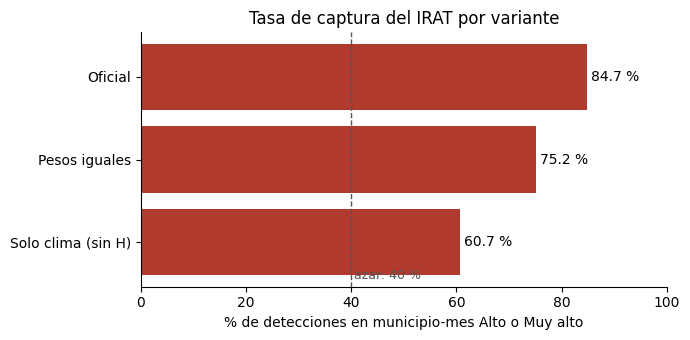

In [4]:
# === Celda 3 · Tasa de captura (K5) y comparación con el azar ===
k5 = res.loc["Oficial", "captura_alto_muy_alto"]
assert abs(k5 - 0.8475) < 0.001, "no coincide con K5 de gold_validation.json"

fig, ax = plt.subplots(figsize=(7, 3.5))
y = res["captura_alto_muy_alto"] * 100
barras = ax.barh(res.index[::-1], y[::-1], color="#b03a2e")
ax.axvline(40, color="#555555", linestyle="--", linewidth=1)
ax.text(40.5, -0.45, "azar: 40 %", color="#555555", fontsize=9)
ax.bar_label(barras, fmt="%.1f %%", padding=3)
ax.set_xlim(0, 100)
ax.set_xlabel("% de detecciones en municipio-mes Alto o Muy alto")
ax.set_title("Tasa de captura del IRAT por variante")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "val01_captura_variantes.png", dpi=200)
plt.show()

**Hallazgo 4.** El IRAT oficial captura el 84,7 % de las detecciones en los municipio-mes clasificados Alto o Muy alto, el mismo valor de K5 en `gold_validation.json`. Como esas dos categorías cubren el 40 % de las celdas, un índice al azar capturaría alrededor del 40 %.

## 5. Sensibilidad: pesos iguales y variante 'solo clima' (sin H)

**Hallazgo 5.** El orden de presentación importa por la circularidad de H (se construye con detecciones pasadas). Solo con el clima, la captura es 60,7 % y el ρ municipal casi desaparece (0,099 concurrente, 0,067 anticipado), aunque a escala departamental se mantiene en 0,241. Con pesos iguales: 75,2 % y ρ = 0,213. Lectura: el clima ordena bien la temporada a escala del departamento, pero no explica *dónde* aparece el fuego dentro de ella; eso lo aporta la propensión histórica de cada municipio, lo que sugiere un régimen dominado por la actividad humana (quemas agrícolas y de pastos), como anticipaba la arquitectura (§7.2).

## 6. Revisión del top 10 de municipio-mes (¿queda alguna fuente industrial?)

In [5]:
# === Celda 4 · Top 10 de municipio-mes por detecciones ===
top = (fmm.nlargest(10, "n_det")
          .merge(dim[["cod_mpio", "nombre"]], on="cod_mpio")
          [["nombre", "cod_mpio", "fecha_mes", "n_det", "irat", "irat_categoria", "c_H"]])
display(top.round(3))
print("detecciones del top 10:", int(top["n_det"].sum()))
# ADR-0005: Socha (15757) y Ráquira (15600) conservan un residuo industrial
print("¿aparece Socha o Ráquira?:", top["cod_mpio"].isin(["15757", "15600"]).any())

,nombre,cod_mpio,fecha_mes,n_det,irat,irat_categoria,c_H
0,MONGUA,15464,2024-01-01,81,0.923,Muy alto,0.986
1,VILLA DE LEYVA,15407,2026-09-01,74,0.690,Muy alto,0.694
2,CHISCAS,15180,2024-01-01,67,0.903,Muy alto,0.982
3,GÜICÁN DE LA SIERRA,15332,2024-02-01,57,0.796,Muy alto,0.977
4,TOTA,15822,2023-02-01,56,0.782,Muy alto,0.927
5,AQUITANIA,15047,2024-01-01,54,0.940,Muy alto,0.971
6,PAYA,15533,2023-02-01,52,0.882,Muy alto,0.989
7,GÜICÁN DE LA SIERRA,15332,2024-01-01,51,0.935,Muy alto,0.959
8,PUERTO BOYACÁ,15572,2024-03-01,49,0.937,Muy alto,0.961
9,CHISCAS,15180,2022-01-01,46,0.647,Muy alto,0.996


detecciones del top 10: 587
¿aparece Socha o Ráquira?: False


**Hallazgo 6.** Los 10 municipio-mes con más detecciones (587 en total) están todos en Muy alto. Son Mongua, Villa de Leyva, Chiscas, Güicán de la Sierra, Tota, Aquitania, Paya y Puerto Boyacá: vertiente oriental y municipios de páramo, los mismos del mapa de densidad del EDA. No aparecen Socha ni Ráquira, los dos municipios con residuo industrial según el ADR-0005, así que en el extremo del ranking no queda contaminación de hornos. Villa de Leyva en septiembre de 2026 viene de datos NRT y es provisional. En 9 de los 10 casos `c_H` ≥ 0,93, lo que confirma el peso de la historia en el índice.

## 7. (P1) Contraste con eventos UNGRD

**No implementado.** El contraste con los eventos de la UNGRD era una tarea P1 (opcional) y quedó fuera del alcance por tiempo. Se declara como trabajo futuro en el IEEE.

## 8. Conclusiones y limitaciones para el IEEE

1. **El índice discrimina.** La tasa de captura del IRAT oficial (84,7 %) duplica la esperada por azar (40 %), y el top 10 de municipio-mes cae entero en Muy alto.
2. **La correlación de rangos es moderada-baja** (ρ = 0,287 concurrente; 0,241 anticipado) por el exceso de ceros (88,7 % de municipio-mes sin detecciones). Para un índice de priorización, la tasa de captura es la métrica más interpretable.
3. **Parte del desempeño es circular.** Sin el componente histórico H, la captura baja a 60,7 % y el ρ municipal a 0,099. Se presenta en ese orden: el clima solo explica 60,7 %; la propensión histórica añade el resto.
4. **Monitoreo antes que pronóstico.** El ρ cae al pasar de *t* a *t*+1, coherente con el EDA.
5. **Limitaciones:** ventana corta (2022 a octubre de 2026); meses de agosto a octubre de 2026 en NRT; enero de 2022 sin historia previa para H; sin validación externa (UNGRD, P1).